# Workshop: train a research agent with RL in ~20 minutes

**The agent.** Kimi K3 answers multi-hop questions from MuSiQue. For each question it gets 20 Wikipedia paragraphs
(2 that answer it, 18 look-alike distractors) and three tools: `search(query)`, `open(doc_id)`, `answer(text)`.
Everything except the model call runs as plain Python on this laptop (`research_env.py`).

**The reward** (the "honest reward"): `correctness x efficiency`.
- correctness = 1 if the answer contains the gold answer (or an alias) and is at most 10 words longer, minus 0.02 per
  extra word; otherwise half the word-overlap score; 0 if it answered without opening a document.
- efficiency = 1 - min(0.06 x calls beyond the ideal 5 + 0.05 x failed calls, 0.25).

**What this notebook does, in order** (time estimates from earlier runs on the serverless pool):

| Step | What happens | Time |
|---|---|---|
| 1-3 | load data, connect, check the prompt renderer, warm up the sampler | ~2 min |
| 4 | **base test**: the untrained model on 13 held-out questions x 4 tries | ~4-5 min |
| 5 | **RL training**: 4 GRPO steps x 4 questions x 4 tries (each step capped at 2.5 min of rollouts) | ~10-12 min |
| 6 | **tuned test**: the same 13 questions x 4 tries | ~4-5 min |
| 7 | results | instant |

**Be honest about what 4 steps can show.** Four steps is enough to watch the loop work (rewards, groups, updates), not
enough to move accuracy reliably; base varies by several points run to run.

**Held-out means leak-free here.** The 13 test questions share no paragraph and no gold answer with any training
question (MuSiQue reuses facts across questions, so holding out question wording alone is not enough).

Needs only `FIREWORKS_API_KEY` in `.env` (copy `.env.example`). `GO = True`.


In [1]:
import collections, json, os, random, sys, time
from concurrent.futures import ThreadPoolExecutor, as_completed
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
ENV_FILE = HERE / ".env"
if ENV_FILE.exists():
    for line in ENV_FILE.read_text().splitlines():
        if "=" in line and not line.strip().startswith("#"):
            k, v = line.split("=", 1)
            os.environ.setdefault(k.strip(), v.strip())
assert os.environ.get("FIREWORKS_API_KEY"), "copy .env.example to .env and set FIREWORKS_API_KEY"

from research_env import SYSTEM_PROMPT, TOOLS, load_questions

DATA = HERE / "data" / "musique_ans_v1.0_dev.jsonl"
if not DATA.exists():
    import urllib.request
    DATA.parent.mkdir(exist_ok=True)
    print("downloading MuSiQue dev set (~29 MB) from Hugging Face ...")
    urllib.request.urlretrieve(
        "https://huggingface.co/datasets/dgslibisey/MuSiQue/resolve/main/musique_ans_v1.0_dev.jsonl", DATA)
print("ready")

ready


## 1. Configuration

Everything you might change is here. `GO = True`.

In [2]:
GO = True
# One switch. Both are on the serverless training pool with tool-capable renderers verified
# token-identical to their chat templates.
MODEL = "kimi-k3"                  # "kimi-k3" or "glm-5p3-flash"
MODELS = {
    "kimi-k3":       dict(base="accounts/fireworks/models/kimi-k3", tokenizer="moonshotai/Kimi-K3",
                          renderer="kimi_k3", max_seq_len=196_608),
    "glm-5p3-flash": dict(base="accounts/fireworks/models/glm-5p3-flash", tokenizer="zai-org/GLM-5.3-Flash",
                          renderer="glm53_low_effort", max_seq_len=65_536),
}
BASE_MODEL      = MODELS[MODEL]["base"]
TOKENIZER_MODEL = MODELS[MODEL]["tokenizer"]
MAX_SEQ_LEN     = MODELS[MODEL]["max_seq_len"]
LORA_RANK       = 64

HOP_TYPE        = "2hop"
TEST_QUESTIONS  = 13              # the leak-free held-out questions
TEST_DRAWS      = 4
K_VALUES        = list(range(1, TEST_DRAWS + 1))

N_STEPS         = 4
TASKS_PER_STEP  = 4
GROUP_SIZE      = 4
LEARNING_RATE   = 1e-4
ADV_CLIP        = 2.0

MAX_TURNS        = 6               # the last turn adds a "call answer now" nudge
MAX_TOKENS       = 10_000          # per turn
COMPLETION_BUDGET_FLOOR = 10_000
assert MAX_TOKENS >= COMPLETION_BUDGET_FLOOR
TEMPERATURE      = 1.0
SAMPLE_TIMEOUT_S = 90              # a healthy turn takes seconds; 600s waits cost the last run 80 minutes
CONCURRENCY      = 8               # training-sampler fan-out cap

TEST_CANDIDATES  = 50              # about half of 2-hop questions are memorized
TRAIN_CANDIDATES = 110             # need N_STEPS x TASKS_PER_STEP = 48 survivors
CLOSED_BOOK_DRAWS_TEST  = 2        # stricter on test: memorized on either draw -> dropped
CLOSED_BOOK_DRAWS_TRAIN = 1

RUNS = HERE / "runs"
RUNS.mkdir(exist_ok=True)
RESUME_RUN_ID    = None            # advanced: continue a dead run
CHECKPOINT_EVERY = 10**6           # no mid-run checkpoints in the workshop
STEP_ROLLOUT_CAP_S = 150           # keep each training step short; unfinished episodes are dropped
RUN_ID = "workshop-" + time.strftime("%Y%m%d-%H%M%S")
PROGRESS = RUNS / f"progress_{RUN_ID}.json"      # hyphens only: checkpoint names are DNS labels

pool = load_questions(DATA, (HOP_TYPE,))
rng = random.Random(1)
rng.shuffle(pool)
test_candidates = pool[:TEST_CANDIDATES]
train_candidates = pool[TEST_CANDIDATES:TEST_CANDIDATES + TRAIN_CANDIDATES]
eps = 2 * TEST_QUESTIONS * TEST_DRAWS + N_STEPS * TASKS_PER_STEP * GROUP_SIZE
print(f"{eps} episodes total, roughly 15-20 minutes end to end")

168 episodes total, roughly 15-20 minutes end to end


## 2. Data: memorized and leaking questions removed

Questions Kimi K3 can answer with no documents are dropped (results are cached in `runs/`, so this is instant after the first run). The test set keeps only questions that share no paragraph or answer with training.

In [3]:
from openai import OpenAI
from research_env import answer_scores, drop_overlap

COMPLETION_BUDGET_FLOOR = 10_000
assert MAX_TOKENS >= COMPLETION_BUDGET_FLOOR
infer = OpenAI(api_key=os.environ["FIREWORKS_API_KEY"], base_url="https://api.fireworks.ai/inference/v1",
               timeout=180.0, max_retries=0)


def closed_book(q):
    for attempt in range(3):
        try:
            r = infer.chat.completions.create(
                model=BASE_MODEL, max_tokens=MAX_TOKENS, temperature=TEMPERATURE, reasoning_effort="low",
                messages=[{"role": "user", "content": q["question"] + "\nAnswer with the short answer only."}])
            break
        except Exception as e:
            if attempt == 2:
                raise
            time.sleep(5 * (attempt + 1))
    content = r.choices[0].message.content
    if not content:
        raise RuntimeError(f"empty closed-book answer for {q['id']} (finish_reason={r.choices[0].finish_reason})")
    return q["id"], answer_scores(content, q)[0]


def memorized_ids(questions, draws, tag):
    cache = RUNS / f"closedbook_{MODEL}_{tag}_{len(questions)}x{draws}.json"
    if cache.exists():
        hit = set(json.loads(cache.read_text()))
        print(f"{tag}: cached closed-book result ({cache.name})")
        return hit
    hit = set()
    with ThreadPoolExecutor(max_workers=CONCURRENCY) as ex:
        futures = [ex.submit(closed_book, q) for q in questions for _ in range(draws)]
        bar = tqdm(as_completed(futures), total=len(futures), desc=f"closed-book {tag}")
        for f in bar:
            qid, exact = f.result()
            if exact:
                hit.add(qid)
            bar.set_postfix(memorized=len(hit))
    cache.write_text(json.dumps(sorted(hit)))
    return hit


if GO:
    mem_test = memorized_ids(test_candidates, CLOSED_BOOK_DRAWS_TEST, "test")
    mem_train = memorized_ids(train_candidates, CLOSED_BOOK_DRAWS_TRAIN, "train")
    unmemorized_test = [q for q in test_candidates if q["id"] not in mem_test][:20]
    train_questions = [q for q in train_candidates if q["id"] not in mem_train]
    # keep only test questions that share no paragraph or gold answer with any training question
    test_questions = [q for q in unmemorized_test if len(drop_overlap(train_questions, [q])) == len(train_questions)]
    print(f"test: {len(mem_test)}/{len(test_candidates)} memorized; {len(test_questions)} of 20 unmemorized questions are leak-free")
    print(f"train: {len(mem_train)}/{len(train_candidates)} memorized, {len(train_questions)} training questions")
    assert len(test_questions) == TEST_QUESTIONS, f"expected {TEST_QUESTIONS} leak-free test questions, got {len(test_questions)}"
    assert len(train_questions) >= TASKS_PER_STEP, "too few unmemorized train questions; raise TRAIN_CANDIDATES"

test: cached closed-book result (closedbook_kimi-k3_test_50x2.json)
train: cached closed-book result (closedbook_kimi-k3_train_110x1.json)
test: 23/50 memorized; 13 of 20 unmemorized questions are leak-free
train: 37/110 memorized, 73 training questions


### What the data looks like

Left: how many questions survive each filter. Below: one held-out task, with the 2 paragraphs that answer it (green) hidden among 18 look-alikes.

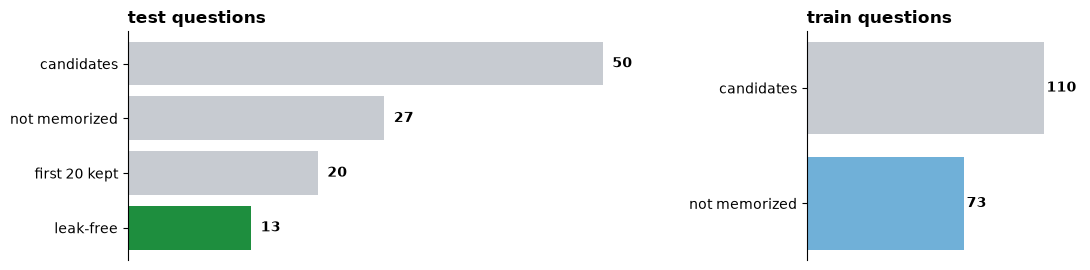

In [4]:
from html import escape
from IPython.display import HTML, display

# where the questions went: each bar is what survives the filter before it
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={"width_ratios": [4, 2]})
funnels = [
    ("test", [("candidates", len(test_candidates)), ("not memorized", len(test_candidates) - len(mem_test)),
              ("first 20 kept", len(unmemorized_test)), ("leak-free", len(test_questions))]),
    ("train", [("candidates", len(train_candidates)), ("not memorized", len(train_questions))]),
]
for ax, (name, stages) in zip(axes, funnels):
    labels, counts = zip(*stages)
    colors = ["#c7cbd1"] * (len(stages) - 1) + ["#1e8e3e" if name == "test" else "#70B0D8"]
    bars = ax.barh(labels[::-1], counts[::-1], color=colors[::-1])
    for b, c in zip(bars, counts[::-1]):
        ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, str(c), va="center", fontweight="bold")
    ax.set_xlim(0, max(counts) * 1.15); ax.set_xticks([])
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.set_title(f"{name} questions", loc="left", fontweight="bold")
fig.tight_layout(); plt.show()

# one held-out task, exactly what the agent gets: a question and 20 paragraphs it has to search
ex = test_questions[0]
support = {h["paragraph_support_idx"]: i + 1 for i, h in enumerate(ex["question_decomposition"])}
chain = " &rarr; ".join(f"<b>hop {i + 1}</b> <code>{escape(h['question'])}</code> = <i>{escape(h['answer'])}</i>"
                        for i, h in enumerate(ex["question_decomposition"]))
tiles = "".join(
    f'<div style="padding:4px 6px;border-radius:4px;font-size:12px;'
    f'background:{"#d7f0dd;border:1px solid #1e8e3e" if p["idx"] in support else "#f1f3f4;border:1px solid #dadce0"}">'
    f'<b>[{p["idx"]}]</b> {escape(p["title"])}{f" <b>(hop {support[p["idx"]]})</b>" if p["idx"] in support else ""}</div>'
    for p in ex["paragraphs"])
evidence = "".join(
    f'<p style="margin:4px 0"><b>hop {support[p["idx"]]} &middot; [{p["idx"]}] {escape(p["title"])}:</b> {escape(p["paragraph_text"])}</p>'
    for p in sorted(ex["paragraphs"], key=lambda p: support.get(p["idx"], 99)) if p["idx"] in support)
display(HTML(f"""
<div style="font-family:sans-serif;max-width:900px">
  <div style="font-size:18px;margin-bottom:4px">&ldquo;{escape(ex['question'])}&rdquo;</div>
  <div style="margin-bottom:8px">gold answer: <b>{escape(ex['answer'])}</b>
    {f"(also accepted: {escape(', '.join(ex['answer_aliases']))})" if ex.get('answer_aliases') else ""}</div>
  <div style="margin-bottom:10px">{chain}</div>
  <div style="display:grid;grid-template-columns:repeat(4,1fr);gap:4px;margin-bottom:10px">{tiles}</div>
  <div style="font-size:13px;color:#3c4043">{evidence}</div>
  <div style="font-size:12px;color:#5f6368;margin-top:6px">The agent sees none of this up front: it must
    <code>search</code> titles and snippets, <code>open</code> the right 2 of 20 paragraphs, then <code>answer</code>.</div>
</div>"""))


## 3. Connect, check the renderer, warm up the sampler

In [5]:
import transformers
from fireworks.training.sdk import FiretitanServiceClient
from fireworks.training.sdk.sampling import AdaptiveConcurrencyController

from research_rollout import GLM53LowEffortRenderer, TOOL_SPECS, rollout_to_datums, run_rollout
from fireworks.training.sdk.client import FIRETITAN_TINKER_CLIENT_CONFIG

import training.renderer  # registers kimi_k3 and glm53
from training.renderer import get_renderer

NO_PYQWEST_CLIENT_CONFIG = {**FIRETITAN_TINKER_CLIENT_CONFIG, "use_pyqwest_transport": False}   # avoids a TLS-certificate error in the pyqwest transport

tokenizer = transformers.AutoTokenizer.from_pretrained(TOKENIZER_MODEL, trust_remote_code=True)
if MODELS[MODEL]["renderer"] == "glm53_low_effort":
    renderer, template_kwargs = GLM53LowEffortRenderer(tokenizer), {"reasoning_effort": "low"}
else:
    renderer, template_kwargs = get_renderer(MODELS[MODEL]["renderer"], tokenizer), {}
_q = test_questions[0]["question"]
_msgs = renderer.create_conversation_prefix_with_tools(TOOL_SPECS, SYSTEM_PROMPT) + [{"role": "user", "content": _q}]
_hf = tokenizer.encode(tokenizer.apply_chat_template(
    [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": _q}],
    tools=TOOLS, tokenize=False, add_generation_prompt=True, **template_kwargs), add_special_tokens=False)
assert renderer.build_generation_prompt(_msgs).to_ints() == _hf, f"renderer differs from the {MODEL} template"
print(f"{MODEL}: renderer matches its chat template ({len(_hf)} tokens)")

service = FiretitanServiceClient(api_key=os.environ["FIREWORKS_API_KEY"],
                                 base_url="https://api.fireworks.ai/training/v1/serverless",
                                 _client_config=NO_PYQWEST_CLIENT_CONFIG)
training_client = service.create_lora_training_client(base_model=BASE_MODEL, rank=LORA_RANK)
start_step = 0
if RESUME_RUN_ID:
    progress = json.loads(PROGRESS.read_text())
    training_client.load_state_with_optimizer(progress["state_path"]).result()
    start_step = progress["next_step"]
    print(f"resumed {RUN_ID} from {progress['state_path']} -> continuing at step {start_step}")


def make_sampler(path):
    return service.create_sampling_client(model_path=path, tokenizer=tokenizer,
                                          concurrency_controller=AdaptiveConcurrencyController())


def snapshot(tag):
    return training_client.save_weights_for_sampler(f"rsch-{RUN_ID}-{tag}").result().path


CLOCK_START = time.time()
clock = lambda: f"{(time.time() - CLOCK_START) / 60:5.1f} min"

base_snap = snapshot("base" if not RESUME_RUN_ID else f"resume{start_step:03d}")
probe = run_rollout(make_sampler(base_snap), renderer, test_questions[0], max_turns=2, max_tokens=MAX_TOKENS,
                    temperature=TEMPERATURE, sample_timeout_s=120)
if probe.sampler_failed:
    raise RuntimeError(f"training sampler not serving ({probe.stop_reason}); stop here rather than queue rollouts")
print(f"[{clock()}] sampler warm: {len(probe.turns)} turn(s), calls {[c['name'] for c in probe.episode.calls]}")

/Users/sinan/forge-workshops/.venv/lib/python3.14/site-packages/fireworks/training/sdk/_core/_compat.py:46: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1.typing import (
Calling super().encode with {'add_special_tokens': False}


kimi-k3: renderer matches its chat template (420 tokens)


prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


[  0.3 min] sampler warm: 2 turn(s), calls ['search', 'answer']


## Rollout helpers

In [6]:
def run_rollouts(sampler, questions, draws, desc, cap_s=None):
    """cap_s: stop waiting after this many seconds and keep the episodes that finished."""
    from concurrent.futures import TimeoutError as FuturesTimeout
    groups, excluded = collections.defaultdict(list), 0
    jobs = [q for _ in range(draws) for q in questions]
    bar = tqdm(total=len(jobs), desc=desc, unit="ep", leave=False)
    ex = ThreadPoolExecutor(max_workers=CONCURRENCY)
    futures = {ex.submit(run_rollout, sampler, renderer, q, max_turns=MAX_TURNS, max_tokens=MAX_TOKENS,
                         temperature=TEMPERATURE, sample_timeout_s=SAMPLE_TIMEOUT_S): q for q in jobs}
    try:
        for f in as_completed(futures, timeout=cap_s):
            r = f.result()
            if r.sampler_failed:
                excluded += 1
            else:
                groups[futures[f]["id"]].append(r)
            bar.update(1)
            rewards = [x.score().reward for rs in groups.values() for x in rs]
            bar.set_postfix(reward=f"{np.mean(rewards):.2f}" if rewards else "-", excluded=excluded)
    except FuturesTimeout:
        cut = sum(not f.done() for f in futures)
        excluded += cut
        tqdm.write(f"[{desc}] rollout cap {cap_s}s reached: {cut} unfinished episodes dropped")
    ex.shutdown(wait=False, cancel_futures=True)
    bar.close()
    return groups, excluded


def load_groups(path):
    """Episodes saved by save_episodes, re-scored from their tool calls, shaped like run_rollouts output."""
    from types import SimpleNamespace
    from research_env import Episode, score as score_episode
    by_id = {q["id"]: q for q in test_questions}
    groups = collections.defaultdict(list)
    for line in path.read_text().splitlines():
        row = json.loads(line)
        ep = Episode(by_id[row["id"]])
        for call in row["calls"]:
            ep.call(call["name"], call["arguments"] if isinstance(call["arguments"], dict) else json.loads(call["arguments"] or "{}"))
        s = score_episode(ep)
        groups[row["id"]].append(SimpleNamespace(score=lambda s=s: s, stop_reason=row["stop_reason"], episode=ep))
    return groups


def advantages(rewards):
    mean = sum(rewards) / len(rewards)
    std = (sum((r - mean) ** 2 for r in rewards) / max(1, len(rewards) - 1)) ** 0.5
    return [max(-ADV_CLIP, min(ADV_CLIP, (r - mean) / (std + 1e-8))) for r in rewards]


def table_row(groups):
    s = [r.score() for rs in groups.values() for r in rs]
    stops = [r.stop_reason for rs in groups.values() for r in rs]
    return {"episodes": len(s), "reward": np.mean([x.reward for x in s]),
            "correctness (F1)": np.mean([x.correctness for x in s]), "correct": np.mean([x.correct for x in s]), "exact match": np.mean([x.exact for x in s]),
            "efficiency": np.mean([x.efficiency for x in s]),
            "perfect": np.mean([x.correct == 1 and x.efficiency == 1 for x in s]),
            "tool calls": np.mean([x.tool_calls for x in s]), "searches": np.mean([x.searches for x in s]),
            "opens": np.mean([x.opens for x in s]), "support recall": np.mean([x.support_recall for x in s]),
            "guessed": np.mean([x.guessed for x in s]), "no answer": np.mean([st != "answered" for st in stops])}
def save_episodes(groups, tag):
    path = RUNS / f"episodes_{RUN_ID}_{tag}.jsonl"
    with path.open("w") as sink:
        for qid, rs in groups.items():
            for r in rs:
                s = r.score()
                sink.write(json.dumps({"id": qid, "stop_reason": r.stop_reason, "final_answer": r.episode.final_answer,
                                       "calls": r.episode.calls, **{k: float(v) for k, v in vars(s).items()}},
                                      default=str) + "\n")
    print(f"saved {sum(map(len, groups.values()))} episodes -> {path.name}")


print("helpers ready")

helpers ready


## 4. Base test: the untrained model

In [7]:
if GO:
    base_groups, base_excl = run_rollouts(make_sampler(base_snap), test_questions, TEST_DRAWS, "base test")
    print(f"[{clock()}] base: reward {table_row(base_groups)['reward']:.3f}, "
          f"correct {table_row(base_groups)['correct']:.1%}, excluded {base_excl}")
    save_episodes(base_groups, "base")

base test:   0%|          | 0/52 [00:00<?, ?ep/s]

prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


[  4.5 min] base: reward 0.228, correct 21.6%, excluded 1
saved 51 episodes -> episodes_workshop-20261022-094238_base.jsonl


## 5. RL training (GRPO)

Each step: 4 training questions, 4 tries each. Tries are scored with the honest reward; within each question, better-than-average tries are reinforced. Each line prints the step's reward and accuracy.

In [8]:
from fireworks.training.sdk import types as fw_types
adam = fw_types.AdamParams(learning_rate=LEARNING_RATE, beta1=0.9, beta2=0.95, eps=1e-12, weight_decay=0.0)
log_path = RUNS / f"grpo_{RUN_ID}.jsonl"
history = [json.loads(line) for line in log_path.read_text().splitlines()] if (RESUME_RUN_ID and log_path.exists()) else []
order = list(train_questions)
random.Random(2).shuffle(order)
snap = base_snap

if GO:
    for step in tqdm(range(start_step, N_STEPS), desc="GRPO", unit="step", initial=start_step, total=N_STEPS):
        if step > start_step:
            snap = snapshot(f"step{step:03d}")
        batch = [order[(step * TASKS_PER_STEP + i) % len(order)] for i in range(TASKS_PER_STEP)]
        groups, excluded = run_rollouts(make_sampler(snap), batch, GROUP_SIZE, f"step {step}", cap_s=STEP_ROLLOUT_CAP_S)
        datums, kept, flat, all_scores = [], 0, 0, []
        for rs in groups.values():
            scores = [r.score() for r in rs]
            all_scores += scores
            rewards = [s.reward for s in scores]
            if len(rewards) < 2 or max(rewards) - min(rewards) < 1e-9:
                flat += 1
                continue
            kept += 1
            for r, adv in zip(rs, advantages(rewards)):
                datums += rollout_to_datums(r, adv, MAX_SEQ_LEN)
        if datums:
            training_client.forward_backward(datums, "importance_sampling").result()
            training_client.optim_step(adam).result()
        row = {"step": step, "clock_min": (time.time() - CLOCK_START) / 60,
               "reward": float(np.mean([s.reward for s in all_scores])) if all_scores else float("nan"),
               "exact": float(np.mean([s.exact for s in all_scores])) if all_scores else float("nan"),
               "correct": float(np.mean([s.correct for s in all_scores])) if all_scores else float("nan"),
               "support_recall": float(np.mean([s.support_recall for s in all_scores])) if all_scores else float("nan"),
               "opens": float(np.mean([s.opens for s in all_scores])) if all_scores else float("nan"),
               "efficiency": float(np.mean([s.efficiency for s in all_scores])) if all_scores else float("nan"),
               "tool_calls": float(np.mean([s.tool_calls for s in all_scores])) if all_scores else float("nan"),
               "groups_kept": kept, "groups_flat": flat, "datums": len(datums), "excluded": excluded}
        history.append(row)
        if (step + 1) % CHECKPOINT_EVERY == 0 and step + 1 < N_STEPS:
            state_path = training_client.save_state(f"rsch-{RUN_ID}-s{step + 1:03d}").result().path
            PROGRESS.write_text(json.dumps({"next_step": step + 1, "state_path": state_path}))
            tqdm.write(f"[{clock()}] durable checkpoint after step {step}: {state_path}")
        with log_path.open("a") as sink:
            sink.write(json.dumps(row) + "\n")
        tqdm.write(f"[{clock()}] step {step}: reward {row['reward']:.3f}, correct {row['correct']:.0%}, "
                   f"support recall {row['support_recall']:.0%}, opens {row['opens']:.1f}, "
                   f"calls {row['tool_calls']:.1f}, kept {kept}/{kept + flat}, excluded {excluded}")
    final_snap = snapshot("final")
    final_state = training_client.save_state(f"rsch-{RUN_ID}-final").result().path
    print(f"[{clock()}] durable checkpoint: {final_state}")

GRPO:   0%|          | 0/4 [00:00<?, ?step/s]

step 0:   0%|          | 0/16 [00:00<?, ?ep/s]

prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


[  6.5 min] step 0: reward 0.371, correct 38%, support recall 41%, opens 1.2, calls 9.2, kept 4/4, excluded 0


step 1:   0%|          | 0/16 [00:00<?, ?ep/s]

...

prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


[ 11.5 min] step 2: reward 0.463, correct 50%, support recall 44%, opens 1.9, calls 6.4, kept 3/4, excluded 0


step 3:   0%|          | 0/16 [00:00<?, ?ep/s]

prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


[ 12.8 min] step 3: reward 0.417, correct 38%, support recall 62%, opens 1.3, calls 5.8, kept 4/4, excluded 0
[ 13.1 min] durable checkpoint: pyroworks/run-b434f3347f4540d78471eea4d2e8f690/rsch-workshop-20261022-094238-final


## 6. Tuned test: same questions, same sampler

In [9]:
if GO:
    tuned_groups, tuned_excl = run_rollouts(make_sampler(final_snap), test_questions, TEST_DRAWS, "tuned test")
    print(f"[{clock()}] TOTAL CLOCK (target 30 min) | tuned excluded {tuned_excl}")
    save_episodes(tuned_groups, "tuned")

tuned test:   0%|          | 0/52 [00:00<?, ?ep/s]

prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


[ 16.2 min] TOTAL CLOCK (target 30 min) | tuned excluded 0
saved 52 episodes -> episodes_workshop-20261022-094238_tuned.jsonl


## 7. Results

**Two numbers, one check.** Both come from `score()` in `research_env.py`.

- **short, correct** (`correct`) is pass/fail per episode: 1 if the answer contains the gold answer (or an alias), is at most 10 words longer, and the agent opened a document; else 0. Averaged, it is plain accuracy.
- **reward** is what RL optimizes: `correctness x efficiency`.
  - correctness grades the same check: 1 minus 0.02 per extra word if it passes, half the word-overlap (F1) if it fails.
  - efficiency discounts extra tool calls: 1.0 at the ideal 5 calls, down to 0.75.

| episode | short, correct | reward |
|---|---|---|
| "Paris", 5 calls | 1 | 1.00 |
| "Paris", 9 calls | 1 | 0.76 |
| "It is Paris, France", 5 calls | 1 | 0.94 |
| wrong, some word overlap | 0 | ~0.1-0.3 |

So reward tracks short, correct when answers are concise and use about 5 calls, and sits below it otherwise.

,base (untrained),after 4 steps (this run)
episodes,51.000,52.000
reward,0.228,0.291
correctness (F1),0.239,0.311
correct,0.216,0.308
exact match,0.157,0.212
efficiency,0.927,0.932
perfect,0.137,0.154
tool calls,6.196,6.058
searches,3.647,3.500
opens,1.549,1.558


after 4 steps (this run)         short, correct  +9.6 pts vs base  (95% -2 to +23)  cannot tell apart from noise


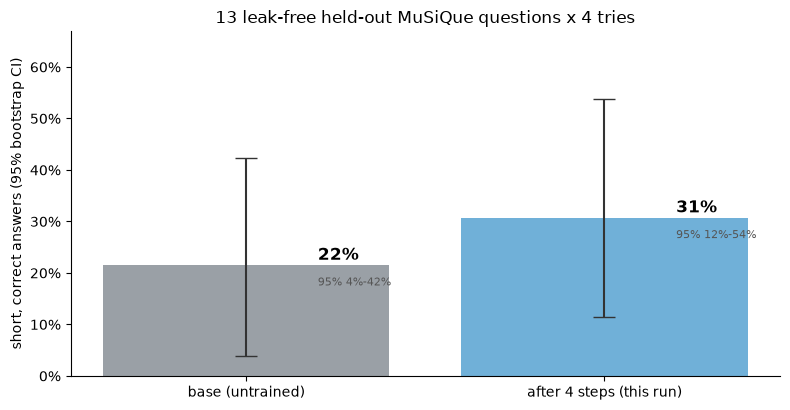

In [10]:
cols = {"base (untrained)": base_groups, f"after {N_STEPS} steps (this run)": tuned_groups}
display(pd.DataFrame({k: table_row(v) for k, v in cols.items()}).round(3))


def per_q(groups):
    return {q: np.mean([r.score().correct for r in rs]) for q, rs in groups.items()}


rng = np.random.default_rng(0)
base_q = per_q(base_groups)
for name, groups in list(cols.items())[1:]:
    other = per_q(groups)
    qs = sorted(set(base_q) & set(other))
    d = np.array([other[q] - base_q[q] for q in qs])
    lo, hi = np.percentile([rng.choice(d, len(d)).mean() for _ in range(10_000)], [2.5, 97.5])
    verdict = "real" if lo > 0 or hi < 0 else "cannot tell apart from noise"
    print(f"{name:32} short, correct {d.mean() * 100:+5.1f} pts vs base  (95% {lo * 100:+.0f} to {hi * 100:+.0f})  {verdict}")

fig, ax = plt.subplots(figsize=(8, 4.2))
names = list(cols)
vals = [table_row(cols[n])["correct"] for n in names]
cis = []
for n in names:
    pq = np.array(list(per_q(cols[n]).values()))
    cis.append(np.percentile([rng.choice(pq, len(pq)).mean() for _ in range(10_000)], [2.5, 97.5]))
err = np.array([[v - lo for v, (lo, _) in zip(vals, cis)], [hi - v for v, (_, hi) in zip(vals, cis)]])
bars = ax.bar(names, vals, yerr=err, capsize=8, ecolor="#333", color=["#9aa0a6", "#70B0D8", "#1e8e3e"][:len(names)])
for b, v, (lo, hi) in zip(bars, vals, cis):
    ax.text(b.get_x() + b.get_width() * 0.75, v + 0.01, f"{v:.0%}", ha="left", fontsize=12, fontweight="bold")
    ax.text(b.get_x() + b.get_width() * 0.75, v - 0.04, f"95% {lo:.0%}-{hi:.0%}", ha="left", fontsize=8, color="#555")
ax.set_ylabel("short, correct answers (95% bootstrap CI)"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, max(hi for _, hi in cis) * 1.15 + 0.05); ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"{TEST_QUESTIONS} leak-free held-out MuSiQue questions x {TEST_DRAWS} tries")
fig.tight_layout(); fig.savefig(HERE / f"fig_{RUN_ID}.png", dpi=150); plt.show()


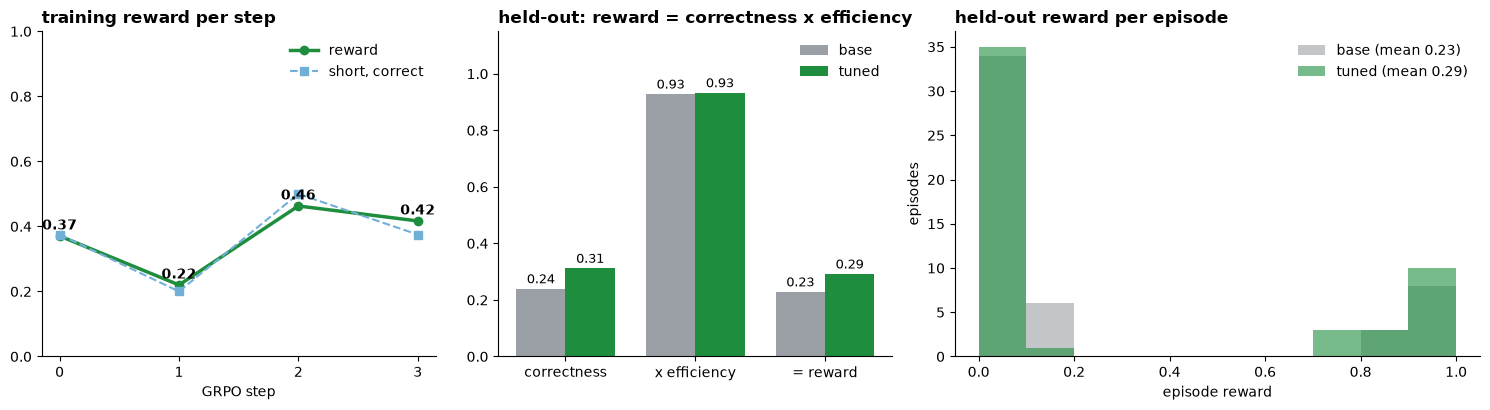

In [11]:
# reward at a glance, read from the files in runs/ so it works after the run (or a kernel restart)
run_id = globals().get("RUN_ID") or sorted(RUNS.glob("grpo_workshop-*.jsonl"))[-1].stem.removeprefix("grpo_")
steps = pd.read_json(RUNS / f"grpo_{run_id}.jsonl", lines=True)
eps = {tag: pd.read_json(RUNS / f"episodes_{run_id}_{tag}.jsonl", lines=True) for tag in ("base", "tuned")}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [3, 3, 4]})

ax = axes[0]
ax.plot(steps["step"], steps["reward"], "o-", color="#1e8e3e", lw=2.5, label="reward")
ax.plot(steps["step"], steps["correct"], "s--", color="#70B0D8", label="short, correct")
for x, y in zip(steps["step"], steps["reward"]):
    ax.text(x, y + 0.02, f"{y:.2f}", ha="center", fontweight="bold")
ax.set_xticks(steps["step"]); ax.set_xlabel("GRPO step"); ax.set_ylim(0, 1); ax.legend(frameon=False)
ax.set_title("training reward per step", loc="left", fontweight="bold")

ax = axes[1]
parts = ["correctness", "efficiency", "reward"]
x = np.arange(len(parts))
for k, (tag, color) in enumerate([("base", "#9aa0a6"), ("tuned", "#1e8e3e")]):
    vals = [eps[tag][p].mean() for p in parts]
    bars = ax.bar(x + (k - 0.5) * 0.38, vals, 0.38, color=color, label=tag)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, ["correctness", "x efficiency", "= reward"]); ax.set_ylim(0, 1.15); ax.legend(frameon=False)
ax.set_title("held-out: reward = correctness x efficiency", loc="left", fontweight="bold")

ax = axes[2]
bins = np.linspace(0, 1, 11)
for tag, color in [("base", "#9aa0a6"), ("tuned", "#1e8e3e")]:
    ax.hist(eps[tag]["reward"], bins=bins, alpha=0.6, color=color, label=f"{tag} (mean {eps[tag]['reward'].mean():.2f})")
ax.set_xlabel("episode reward"); ax.set_ylabel("episodes"); ax.legend(frameon=False)
ax.set_title("held-out reward per episode", loc="left", fontweight="bold")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

## 8. Promote the trained checkpoint to a model

Registers the final sampler checkpoint as a Fireworks model and writes its id to `runs/promoted_model.txt`. 
`workshop_langchain_research_agent.ipynb` reads that file, deploys the model, and compares it to the base model.

In [12]:
from fireworks.training.sdk.fireworks_client import FireworksClient

fw = FireworksClient(api_key=os.environ["FIREWORKS_API_KEY"])
_, trainer_run, snap_name = final_snap.split("/")
ckpt_id = f"{trainer_run}-{snap_name}"
rows = fw.list_training_session_checkpoints(service.training_session_name)
ckpt = next(r for r in rows if r["name"].endswith(f"/{ckpt_id}") and r.get("promotable"))
promoted = fw.promote_session_checkpoint(name=ckpt["name"], output_model_id=f"rsch-{RUN_ID}", base_model=BASE_MODEL)
PROMOTED_MODEL = f"accounts/{fw.account_id}/models/rsch-{RUN_ID}"
(RUNS / "promoted_model.txt").write_text(PROMOTED_MODEL)
print(PROMOTED_MODEL, promoted.get("state"))

accounts/pyroworks/models/rsch-workshop-20261022-094238 READY


In [13]:
service.close()
print("service closed")

service closed
